(40000, 30) (10000, 30)
best_params_ = {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 5}
best_score_  = 0.3411
humid         0.200049
temp          0.129963
sched_hour    0.127947
distance      0.113647
day           0.109028
wind_speed    0.076584
month         0.071820
seats         0.048897
precip        0.020914
visib         0.020207
dtype: float64


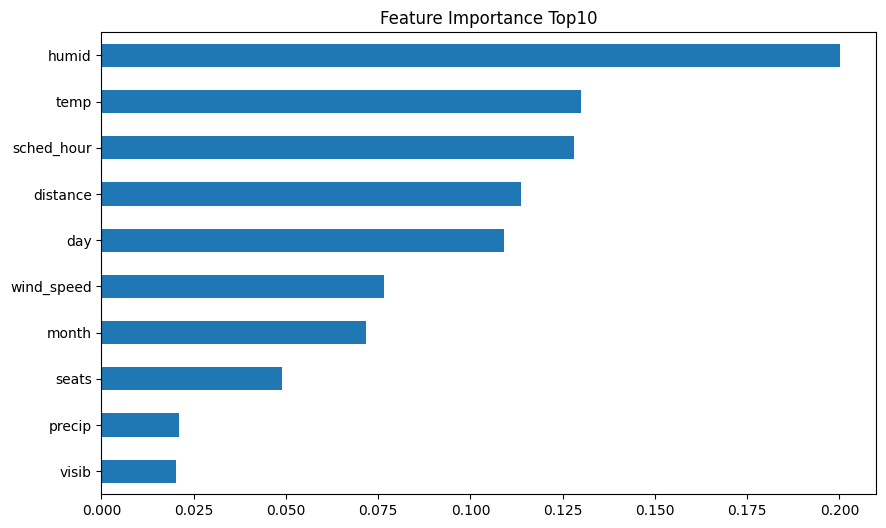

best_params_ = {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 300}
best_score_  = 0.3779
carrier_EV    0.085961
sched_hour    0.061359
month         0.048583
precip        0.047223
carrier_DL    0.043920
humid         0.042424
origin_JFK    0.041945
carrier_US    0.039761
day           0.039382
carrier_WN    0.039307
dtype: float32


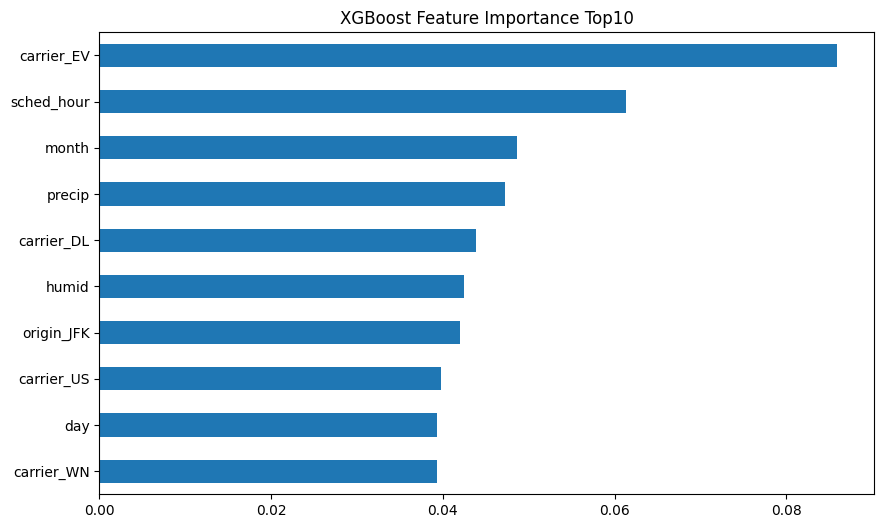

In [1]:
# 코드_공유.py
# 작업자 A, B, Admin 이 함께 사용하는 파일입니다.

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

# 2013년 뉴욕 출발 항공편 표본 50,000건입니다.
# 항공편 정보에 기상 정보와 기체 정보를 미리 결합해 두었습니다.
df = pd.read_csv('flights_ml.csv')

NUM = ['month', 'day', 'sched_hour', 'distance', 'temp', 'humid',
       'wind_speed', 'precip', 'visib', 'seats', 'engines']
CAT = ['carrier', 'origin']

X = pd.get_dummies(df[NUM + CAT], columns=CAT)
X = X.fillna(X.median(numeric_only=True))
y = df['is_delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)


####### A 작업자 작업 수행 #######

''' 코드 작성 바랍니다 '''

from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "criterion" : ['gini', 'entropy'],
    "max_depth" : [5 ,10, 15],
    "min_samples_leaf" : [1, 5, 20]
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,               
    scoring='f1'      
)

grid.fit(X_train, y_train)

print('best_params_ =', grid.best_params_)
print('best_score_  = %.4f' % grid.best_score_)

model = grid.best_estimator_

imp = pd.Series(model.feature_importances_, index = X_train.columns)
top10 = imp.sort_values(ascending=False).head(10)
print(top10)

plt.figure(figsize=(10,6))
top10.sort_values().plot(kind='barh')
plt.title('Feature Importance Top10')
plt.show()


####### B 작업자 작업 수행 #######

''' 코드 작성 바랍니다 '''

from xgboost import XGBClassifier

param_grid_xgb = {
    "max_depth" : [3, 6, 9],
    "n_estimators" : [100, 300],
    "learning_rate" : [0.1, 0.05]
}

grid_xgb = GridSearchCV(
    estimator= XGBClassifier(random_state=42),
    param_grid = param_grid_xgb,
    cv =5,
    scoring='f1'
)

grid_xgb.fit(X_train, y_train)

print('best_params_ =', grid_xgb.best_params_)
print('best_score_  = %.4f' % grid_xgb.best_score_)

model_xgb = grid_xgb.best_estimator_

imp_xgb = pd.Series(model_xgb.feature_importances_, index = X_train.columns)
top10_xgb = imp_xgb.sort_values(ascending=False).head(10)
print(top10_xgb)

plt.figure(figsize=(10,6))
top10_xgb.sort_values().plot(kind='barh')
plt.title('XGBoost Feature Importance Top10')
plt.show()


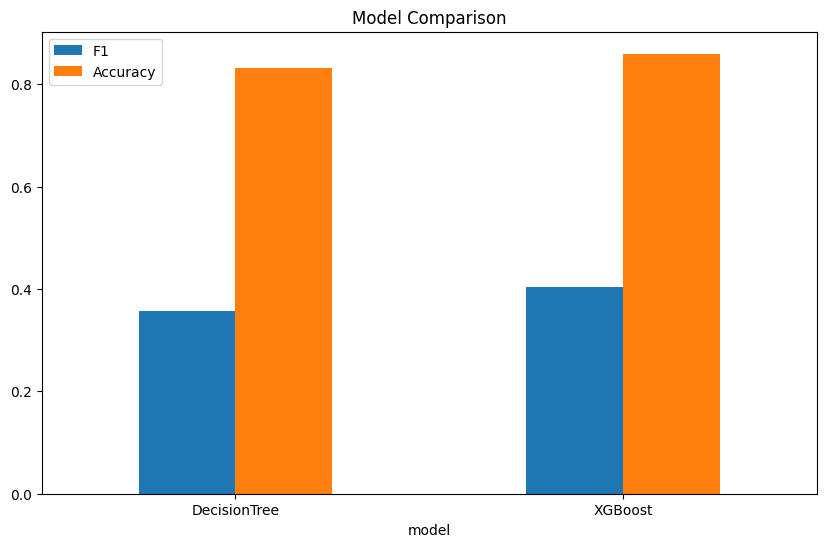

In [7]:
from sklearn.metrics import f1_score, accuracy_score

models = {
  'DecisionTree' : model,
  'XGBoost' : model_xgb
}

rows= []

for name, m in models.items():
  pred = m.predict(X_test)
  rows.append({
    'model' : name,
    'F1' : f1_score(y_test, pred),
    'Accuracy' : accuracy_score(y_test, pred)
  })

result_df = pd.DataFrame(rows).set_index('model')
result_df.plot(kind='bar', figsize=(10,6))

plt.title('Model Comparison')
plt.xticks(rotation=0)
plt.show()

In [8]:
import subprocess
print(subprocess.run(['git', 'log', '--oneline', '-n', '20'],
                     capture_output=True, text=True).stdout)

b1f7b56 Merge pull request #2 from happysy07/B_branch
153ec5e Merge branch 'main' into B_branch
1a1311f XGBoost 모델링 코드 추가
e88a620 DecisionTree 하이퍼파라미터 후보 조정"
8cb48e3 Merge pull request #1 from happysy07/A_branch
96133e4 DecisionTree 모델링 코드 추가
09968cf 작업 공간 생성

